In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df_dados = pd.read_excel('/content/drive/MyDrive/dadosexp1.xlsx')

In [ ]:
df_dados.describe()

,⟨I⟩ (V),λ (nm),uₑ(I) (V)
count,25.000000,25.000000,25.000000
mean,0.209820,607.400000,0.000816
std,0.023155,152.957783,0.000140
min,0.181200,400.000000,0.000600
25%,0.185000,495.000000,0.000700
50%,0.209200,580.000000,0.000800
75%,0.231200,680.000000,0.000900
max,0.241200,950.000000,0.001000


In [ ]:
df_dados.head()

,⟨I⟩ (V),λ (nm),uₑ(I) (V)
0,0.1840,400,0.0007
1,0.1828,405,0.0008
2,0.1820,410,0.0006
3,0.1812,455,0.0006
4,0.1813,470,0.0007


In [ ]:
df_dados = df_dados.rename(columns={"⟨I⟩ (V)": "intensidade"})
df_dados = df_dados.rename(columns={"λ (nm)": "lambda"})
df_dados = df_dados.rename(columns={"uₑ(I) (V)": "erros"})
df_dados.head()

,intensidade,lambda,erros
0,0.1840,400,0.0007
1,0.1828,405,0.0008
2,0.1820,410,0.0006
3,0.1812,455,0.0006
4,0.1813,470,0.0007


In [ ]:
df_dados["intensidade"].describe()

,intensidade
count,25.000000
mean,0.209820
std,0.023155
min,0.181200
25%,0.185000
50%,0.209200
75%,0.231200
max,0.241200


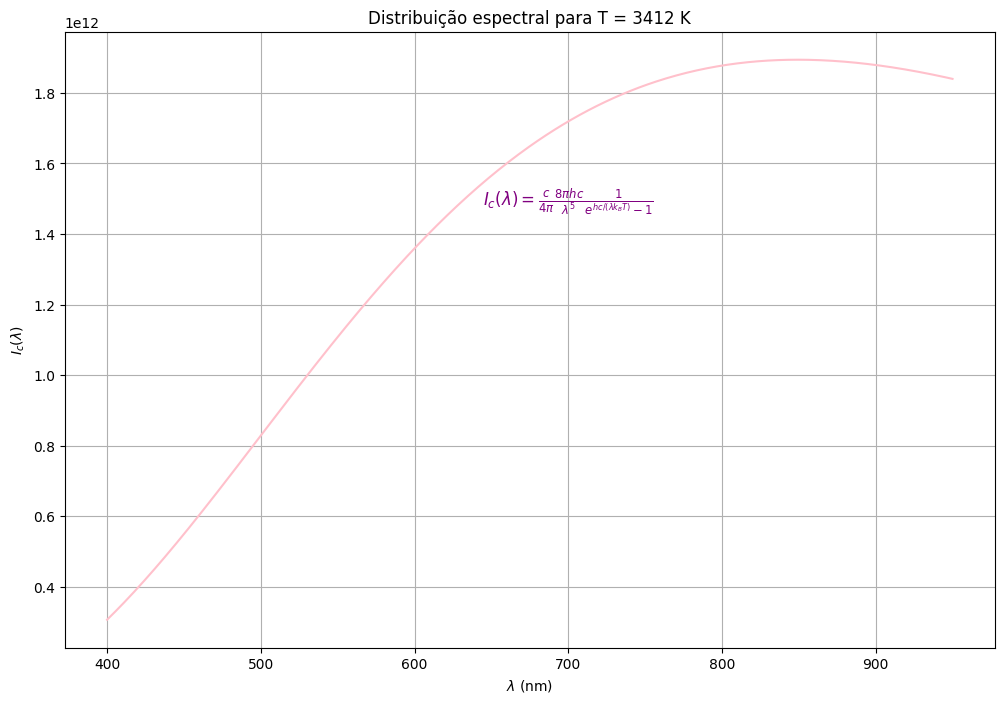

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Constantes
h = 6.62607015e-34      # J.s
c = 2.99792458e8        # m/s
kB = 1.380649e-23       # J/K

T = 3412                # K

def uc(lamb):
    return (8*np.pi*h*c / lamb**5) / (np.exp(h*c/(lamb*kB*T)) - 1)

def Ic(lamb):
    return (c/(4*np.pi)) * uc(lamb)

# Comprimentos de onda: 400 a 950 nm
lamb = np.linspace(400e-9, 950e-9, 500)

# Intensidade
I = Ic(lamb)

# Gráfico
plt.subplots(figsize=(12,8))
plt.plot(lamb*1e9, I, color='pink')


plt.xlabel(r'$\lambda$ (nm)')
plt.ylabel(r'$I_c(\lambda)$')
plt.title('Distribuição espectral para T = 3412 K')




plt.text(0.45, 0.75, r'$I_c(\lambda)=\frac{c}{4\pi}\frac{8\pi hc}{\lambda^5}'
    r'\frac{1}{e^{hc/(\lambda k_BT)}-1}$',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top', color='purple'
)
plt.grid()

plt.show()

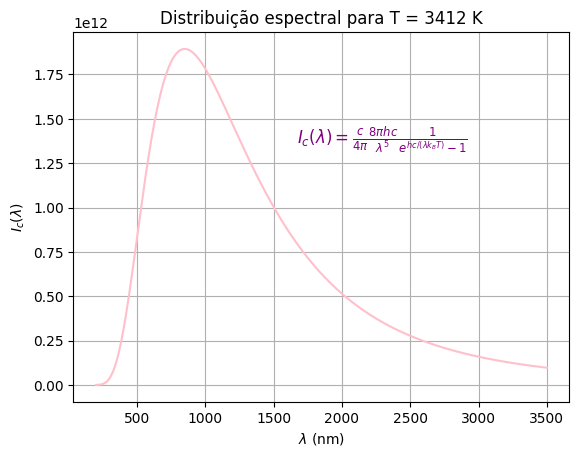

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Constantes
h = 6.62607015e-34      # J.s
c = 2.99792458e8        # m/s
kB = 1.380649e-23       # J/K

T = 3412                # K

def uc(lamb):
    return (8*np.pi*h*c / lamb**5) / (np.exp(h*c/(lamb*kB*T)) - 1)

def Ic(lamb):
    return (c/(4*np.pi)) * uc(lamb)

# Comprimentos de onda: 400 a 950 nm
lamb = np.linspace(200e-9, 3500e-9, 500)

# Intensidade
I = Ic(lamb)

# Gráfico
plt.plot(lamb*1e9, I, color='pink')

plt.xlabel(r'$\lambda$ (nm)')
plt.ylabel(r'$I_c(\lambda)$')
plt.title('Distribuição espectral para T = 3412 K')
plt.text(0.45, 0.75, r'$I_c(\lambda)=\frac{c}{4\pi}\frac{8\pi hc}{\lambda^5}'
    r'\frac{1}{e^{hc/(\lambda k_BT)}-1}$',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top', color='purple'
)
plt.grid()

plt.show()

<ErrorbarContainer object of 3 artists>

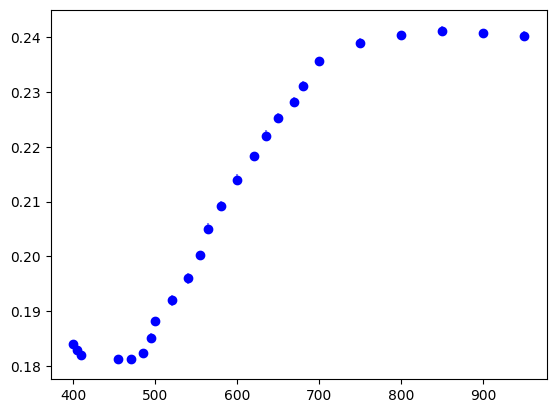

In [ ]:
plt.scatter(df_dados['lambda'], df_dados['intensidade'], color='blue')
plt.errorbar(df_dados['lambda'], df_dados['intensidade'],yerr=df_dados['erros'],fmt='.', color='blue', alpha=0.5)

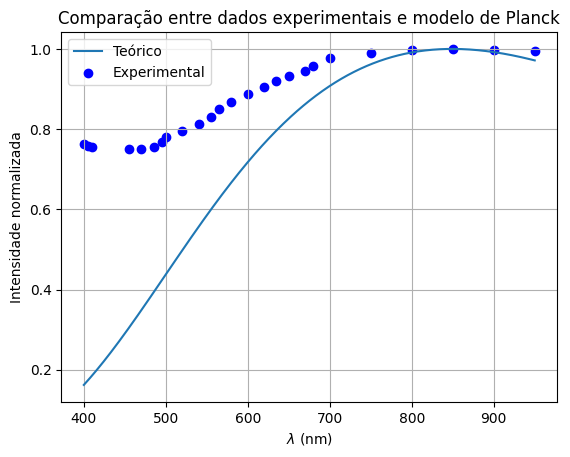

In [ ]:
# Dados experimentais
lambda_exp = df_dados['lambda'].values
I_exp = df_dados['intensidade'].values

# Curva teórica
lamb = np.linspace(400e-9, 950e-9, 500)
I_teorica = Ic(lamb)

# Normalização
I_exp_norm = I_exp / I_exp.max()
I_teorica_norm = I_teorica / I_teorica.max()

# Gráfico
plt.plot(lamb*1e9, I_teorica_norm, label='Teórico')
plt.scatter(lambda_exp, I_exp_norm, color='blue', label='Experimental')

plt.xlabel(r'$\lambda$ (nm)')
plt.ylabel(r'Intensidade normalizada')
plt.title('Comparação entre dados experimentais e modelo de Planck')
plt.grid()
plt.legend()
plt.show()

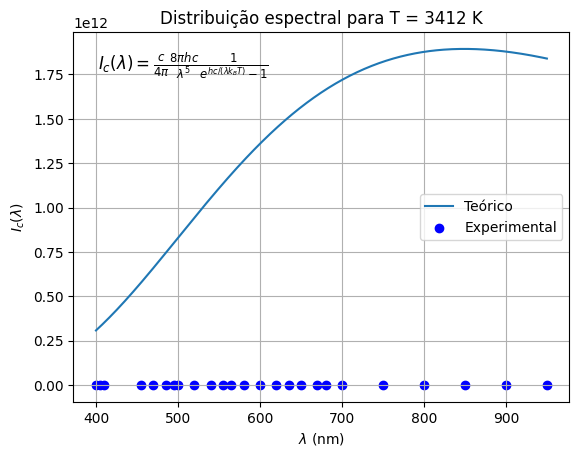

In [ ]:
# Curva teórica
lamb = np.linspace(400e-9, 950e-9, 500)
I = Ic(lamb)

# Dados experimentais
lambda_exp = df_dados['lambda']
I_exp = df_dados['intensidade']

# Gráfico
plt.plot(lamb*1e9, I, label='Teórico')
plt.scatter(lambda_exp, I_exp, color='blue', label='Experimental')

# Equação no gráfico
plt.text(
    0.05, 0.95,
    r'$I_c(\lambda)=\frac{c}{4\pi}\frac{8\pi hc}{\lambda^5}'
    r'\frac{1}{e^{hc/(\lambda k_BT)}-1}$',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top'
)

plt.xlabel(r'$\lambda$ (nm)')
plt.ylabel(r'$I_c(\lambda)$')
plt.title('Distribuição espectral para T = 3412 K')
plt.grid()
plt.legend()
plt.show()

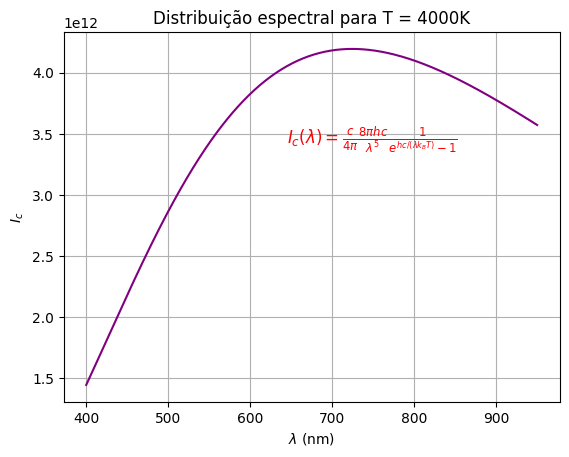

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Constantes
h = 6.62607015e-34      # J.s
c = 2.99792458e8        # m/s
kB = 1.380649e-23       # J/K

T = 4000                # K

def uc(lamb):
    return (8*np.pi*h*c / lamb**5) / (np.exp(h*c/(lamb*kB*T)) - 1)

def Ic(lamb):
    return (c/(4*np.pi)) * uc(lamb)

# Comprimentos de onda: 400 a 950 nm
lamb = np.linspace(400e-9, 950e-9, 500)

# Intensidade
I = Ic(lamb)

# Gráfico
plt.plot(lamb*1e9, I, color='purple')

plt.xlabel(r'$\lambda$ (nm)')
plt.ylabel(r'$I_c$')
plt.title('Distribuição espectral para T = 4000K')
plt.text(0.45, 0.75, r'$I_c(\lambda)=\frac{c}{4\pi}\frac{8\pi hc}{\lambda^5}'
    r'\frac{1}{e^{hc/(\lambda k_BT)}-1}$',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top', color='red'
)
plt.grid()

plt.show()

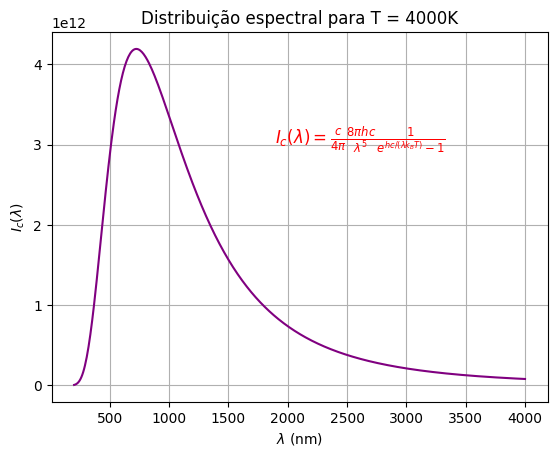

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Constantes
h = 6.62607015e-34      # J.s
c = 2.99792458e8        # m/s
kB = 1.380649e-23       # J/K

T = 4000                # K

def uc(lamb):
    return (8*np.pi*h*c / lamb**5) / (np.exp(h*c/(lamb*kB*T)) - 1)

def Ic(lamb):
    return (c/(4*np.pi)) * uc(lamb)

# Comprimentos de onda: 400 a 950 nm
lamb = np.linspace(200e-9, 4000e-9, 500)

# Intensidade
I = Ic(lamb)

# Gráfico
plt.plot(lamb*1e9, I, color='purple')

plt.xlabel(r'$\lambda$ (nm)')
plt.ylabel(r'$I_c(\lambda)$')
plt.title('Distribuição espectral para T = 4000K')
plt.text(0.45, 0.75, r'$I_c(\lambda)=\frac{c}{4\pi}\frac{8\pi hc}{\lambda^5}'
    r'\frac{1}{e^{hc/(\lambda k_BT)}-1}$',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top', color='red'
)
plt.grid()

plt.show()

In [ ]:
df_dados2 = pd.read_excel('/content/drive/MyDrive/dados2ex1.xlsx')

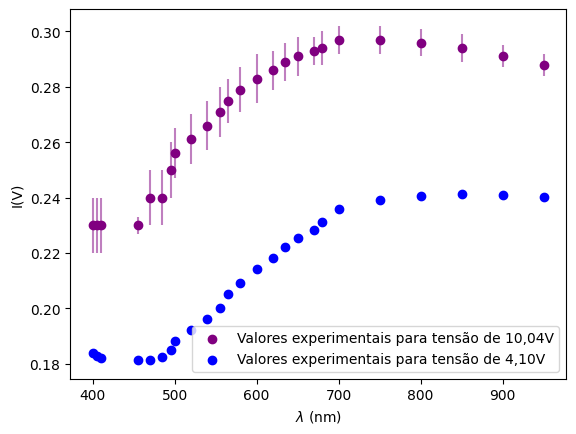

In [ ]:
plt.xlabel(r'$\lambda$ (nm)')
plt.ylabel(r'I (V)')

plt.scatter(df_dados2['lambda'], df_dados2['intensidade'], color='purple', label="Valores experimentais para tensão de 10,04V")
plt.errorbar(df_dados2['lambda'], df_dados2['intensidade'],yerr=df_dados2['erros'],fmt='.', color='purple', alpha=0.5)

plt.scatter(df_dados['lambda'], df_dados['intensidade'], color='blue', label="Valores experimentais para tensão de 4,10V")
plt.errorbar(df_dados['lambda'], df_dados['intensidade'],yerr=df_dados['erros'],fmt='.', color='blue', alpha=0.5)

plt.legend()


In [ ]:
import numpy as np

# Constantes
h = 6.62607015e-34
c = 2.99792458e8
kB = 1.380649e-23

# Temperatura fixa
T = 3412  # K

# Dados experimentais
lambda_nm = df_dados['lambda'].values
V = df_dados['intensidade'].values
sigma = df_dados['erros'].values


# Converter nm -> m
lamb = lambda_nm * 1e-9

# Modelo de Planck
def Ic(lamb, T):
    return (2*h*c**2 / lamb**5) / (
        np.exp(h*c/(lamb*kB*T)) - 1
    )

# Intensidade teórica para T fixo
I = Ic(lamb, T)

# MMQ: melhor valor de A
A = np.sum(I * V / sigma**2) / np.sum(I**2 / sigma**2)

# Calcula chi²
V_modelo = A * I
chi2 = np.sum(((V - V_modelo) / sigma)**2)

print("T =", T, "K")
print("A =", A)
print("chi² =", chi2)

T = 3412 K
A = 1.5185044084617674e-13
chi² = 197346.12338803036


In [ ]:
import numpy as np

# Constantes
h = 6.62607015e-34
c = 2.99792458e8
kB = 1.380649e-23

# Temperatura fixa
T = 4000  # K

# Dados experimentais
lambda_nm = df_dados2['lambda'].values
V = df_dados2['intensidade'].values
sigma = df_dados2['erros'].values


# Converter nm -> m
lamb = lambda_nm * 1e-9

# Modelo de Planck
def Ic(lamb, T):
    return (2*h*c**2 / lamb**5) / (
        np.exp(h*c/(lamb*kB*T)) - 1
    )

# Intensidade teórica para T fixo
I = Ic(lamb, T)

# MMQ: melhor valor de A
A = np.sum(I * V / sigma**2) / np.sum(I**2 / sigma**2)

# Calcula chi²
V_modelo = A * I
chi2 = np.sum(((V - V_modelo) / sigma)**2)

print("T =", T, "K")
print("A =", A)
print("chi² =", chi2)

T = 4000 K
A = 7.722644483708709e-14
chi² = 960.609715831404


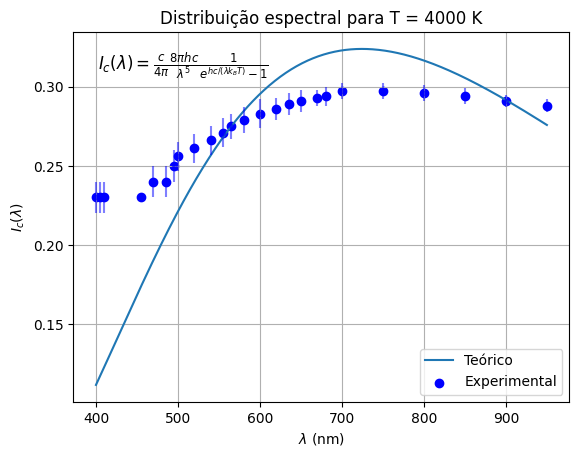

In [ ]:
# Curva teórica
lamb = np.linspace(400e-9, 950e-9, 500)
I = 7.72*10**(-14)*Ic(lamb,4000)

# Dados experimentais
lambda_exp = df_dados2['lambda']
I_exp = df_dados2['intensidade']

# Gráfico
plt.plot(lamb*1e9, I, label='Teórico')
plt.scatter(lambda_exp, I_exp, color='blue', label='Experimental')
plt.errorbar(df_dados2['lambda'], df_dados2['intensidade'],yerr=df_dados2['erros'],fmt='.', color='blue', alpha=0.5)

# Equação no gráfico
plt.text(
    0.05, 0.95,
    r'$I_c(\lambda)=\frac{c}{4\pi}\frac{8\pi hc}{\lambda^5}'
    r'\frac{1}{e^{hc/(\lambda k_BT)}-1}$',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top'
)

plt.xlabel(r'$\lambda$ (nm)')
plt.ylabel(r'$I_c(\lambda)$')
plt.title('Distribuição espectral para T = 4000 K')
plt.grid()
plt.legend()
plt.show()